# Fundamentals of Data Science (22CSC59) — Case Studies 1 and 4
**Name:** Neha Samanvitha Valiveti &nbsp;|&nbsp; **Roll No:** 160124733159 &nbsp;|&nbsp; **Class:** B.E. CSE, III Year, V Semester, Section 3  
**Faculty:** Smt. S. Durga Devi &nbsp;|&nbsp; Chaitanya Bharathi Institute of Technology (A), Hyderabad

This notebook has two independent parts:
- **Part A — Case Study 1:** Transaction analysis and clustering of online retail shopping baskets (`Online_retail_new.csv`)
- **Part B — Case Study 4:** Predicting student dropout and academic success (`Studentdata.csv`)

Each code cell is preceded by an explanation of its purpose and followed by the observations obtained. Run all cells from top to bottom; place both CSV files in the same folder as this notebook.

---
# Part A — Case Study 1: Online Retail Transaction Clustering
**Problem statement:** the online store has transaction records with several products bought together but no systematic analysis of transaction characteristics or groups of similar baskets. The objective is to analyse the data statistically, represent baskets numerically, apply PCA, compare four clustering algorithms (K-means, hierarchical, DBSCAN, spectral) using the silhouette coefficient and Davies–Bouldin index, and draw business conclusions.

### A.0 Setup
**Purpose:** import the libraries used in Part A (Pandas for data handling, Scikit-learn for PCA and clustering, SciPy for the dendrogram, Matplotlib/Seaborn for plots) and fix a random seed so every result is reproducible. A helper `save()` stores each figure in `figures/` for the PDF report.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid'); os.makedirs('figures', exist_ok=True)
RANDOM_STATE = 42
def save(name): plt.tight_layout(); plt.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight'); plt.show()

### A.1 Loading the dataset
**Purpose:** read the transaction file. Each row is one shopping basket and each column is an item *slot*, not a fixed product. The file has **no header row**: its first line (shrimp, almonds, avocado, …) is a real basket, so `header=None` is used to avoid losing it and to avoid treating product names as column names.

In [2]:
raw = pd.read_csv('Online_retail_new.csv', header=None)
print('Shape (rows = transactions, columns = item slots):', raw.shape)
raw.head()

Shape (rows = transactions, columns = item slots): (7501, 20)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,shrimp,almonds,avocado,vegetables mix,green grapes,whole weat flour,yams,cottage cheese,energy drink,tomato juice,low fat yogurt,green tea,honey,salad,mineral water,salmon,antioxydant juice,frozen smoothie,spinach,olive oil
1,burgers,meatballs,eggs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,chutney,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,turkey,avocado,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,mineral water,milk,energy bar,whole wheat rice,green tea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### A.2 Understanding the structure
**Purpose:** measure how much of the grid is empty, check for formatting problems and count repeated baskets before cleaning.

**Observation:** the 7,501 × 20 grid holds only 29,363 item entries; the remaining ~80% of cells are empty slots because most baskets are small. One value carries extra whitespace. 2,325 rows are exact repeats of another basket. These are **not** removed: popular small baskets (e.g. a single bottle of mineral water) are genuinely bought many times, and deleting them would distort product frequencies.

In [3]:
items_long = raw.stack().dropna()
print('Non-empty item cells        :', len(items_long))
print('Empty slots (NaN)           :', raw.isna().sum().sum())
print('Values with extra whitespace:', (items_long != items_long.str.strip()).sum())
print('Fully identical transactions:', raw.duplicated().sum())

Non-empty item cells        : 29363
Empty slots (NaN)           : 120657
Values with extra whitespace: 1
Fully identical transactions: 2325


### A.3 Cleaning and preprocessing with Pandas
**Purpose:** convert each row into a clean list of products: drop empty slots, strip whitespace, lower-case the names, and remove items listed twice in the same basket (a basket either contains a product or it does not).

**Observation:** 5 baskets contained a repeated item and were de-duplicated. No baskets became empty, so all 7,501 transactions are kept, covering 119 distinct products.

In [4]:
baskets = raw.apply(lambda r: sorted({str(x).strip().lower() for x in r.dropna() if str(x).strip()}), axis=1)
dup_inside = sum(raw.loc[i].notna().sum() != len(b) for i, b in baskets.items())
print('Baskets where an item was listed twice (deduplicated):', dup_inside)
baskets = baskets[baskets.str.len() > 0].reset_index(drop=True)
tx = pd.DataFrame({'items': baskets, 'size': baskets.str.len()})
print('Transactions after cleaning:', len(tx), '| unique products:', tx['items'].explode().nunique())
tx.head()

Baskets where an item was listed twice (deduplicated): 5
Transactions after cleaning: 7501 | unique products: 119


,items,size
0,"[almonds, antioxydant juice, avocado, cottage ...",20
1,"[burgers, eggs, meatballs]",3
2,[chutney],1
3,"[avocado, turkey]",2
4,"[energy bar, green tea, milk, mineral water, w...",5


### A.4 Descriptive statistics of transaction size
**Purpose:** summarise how many products customers buy per visit.

**Observation:** the mean basket has 3.91 items but the median is 3 and the most common size is 1. The distribution is right-skewed (skewness 1.19): 23.4% of baskets contain a single product, while a small number of large baskets (up to 20 items) pull the mean upwards. The median is therefore the better "typical basket" figure.

In [5]:
print(tx['size'].describe().round(2))
print('Mode basket size:', tx['size'].mode()[0], '| skewness:', round(tx['size'].skew(), 2))
print('Share of single-item baskets: {:.1%}'.format((tx['size'] == 1).mean()))

count    7501.00
mean        3.91
std         2.90
min         1.00
25%         2.00
50%         3.00
75%         5.00
max        20.00
Name: size, dtype: float64
Mode basket size: 1 | skewness: 1.19
Share of single-item baskets: 23.4%


### A.5 Frequently occurring products
**Purpose:** compute each product's *support*, the percentage of transactions that contain it.

**Observation:** mineral water is in 23.8% of all baskets, followed by eggs (18.0%), spaghetti (17.4%), french fries (17.1%) and chocolate (16.4%). Demand is concentrated: 44 of the 119 products appear in fewer than 1% of baskets.

In [6]:
freq = tx['items'].explode().value_counts()
support = (freq / len(tx)).rename('support')
top = pd.DataFrame({'count': freq, 'support_%': (support * 100).round(2)}).head(15)
print(top)
print('\nProducts appearing in < 1% of baskets:', (support < 0.01).sum(), 'of', len(support))

                   count  support_%
items                              
mineral water       1788      23.84
eggs                1348      17.97
spaghetti           1306      17.41
french fries        1282      17.09
chocolate           1229      16.38
green tea            991      13.21
milk                 972      12.96
ground beef          737       9.83
frozen vegetables    715       9.53
pancakes             713       9.51
burgers              654       8.72
cake                 608       8.11
cookies              603       8.04
escalope             595       7.93
low fat yogurt       574       7.65

Products appearing in < 1% of baskets: 44 of 119


### A.6 Visualising product frequencies
**Interpretation:** the bar chart shows a long-tail pattern. A handful of everyday staples dominate, and support falls quickly after the top seven products (all above 12%). These staples will heavily influence any similarity measure between baskets.

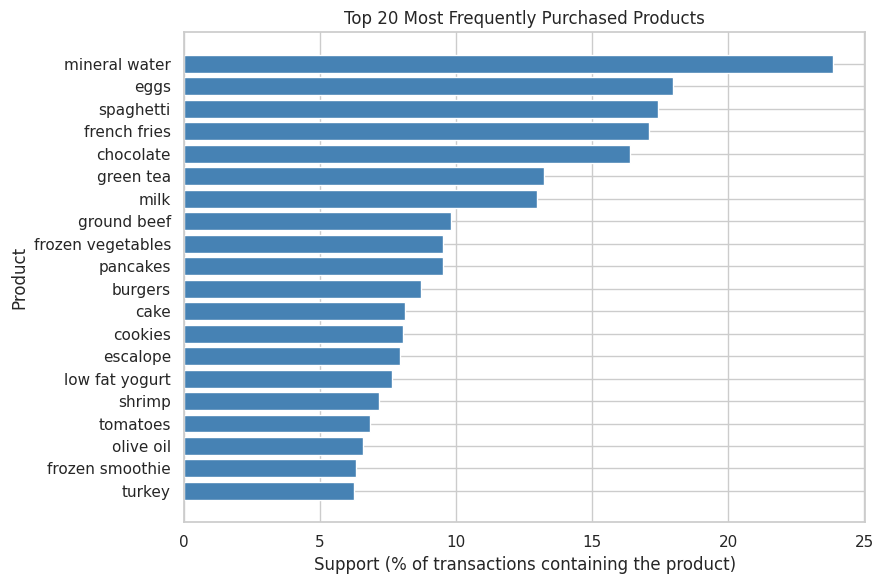

In [7]:
plt.figure(figsize=(9, 6))
t20 = support.head(20)[::-1] * 100
plt.barh(t20.index, t20.values, color='steelblue')
plt.title('Top 20 Most Frequently Purchased Products')
plt.xlabel('Support (% of transactions containing the product)'); plt.ylabel('Product')
save('cs1_top20_products')

### A.7 Visualising transaction-size distribution
**Interpretation:** the histogram falls steadily from size 1 onwards. The mean line (red) sits to the right of the median (green), confirming the right skew. Most customers make short top-up trips rather than large weekly shops.

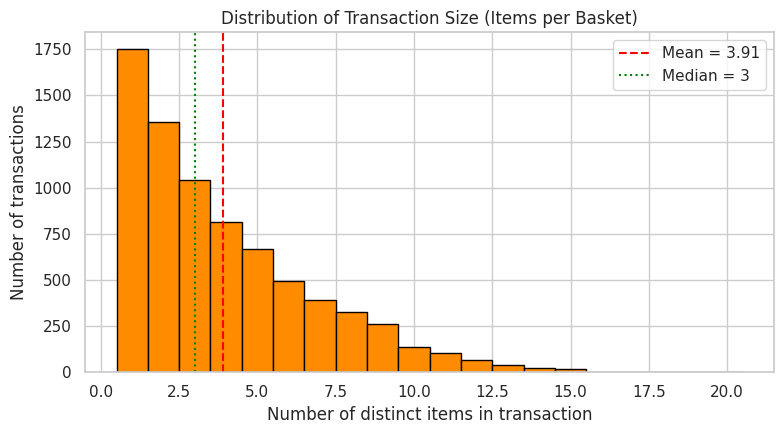

In [8]:
plt.figure(figsize=(8, 4.5))
plt.hist(tx['size'], bins=range(1, tx['size'].max() + 2), color='darkorange', edgecolor='black', align='left')
plt.axvline(tx['size'].mean(), color='red', ls='--', label=f"Mean = {tx['size'].mean():.2f}")
plt.axvline(tx['size'].median(), color='green', ls=':', label=f"Median = {tx['size'].median():.0f}")
plt.title('Distribution of Transaction Size (Items per Basket)')
plt.xlabel('Number of distinct items in transaction'); plt.ylabel('Number of transactions'); plt.legend()
save('cs1_transaction_size')

### A.8 Representing transactions as numerical feature vectors
**Purpose:** clustering needs numbers, so each basket becomes a 119-length binary vector (1 = product present, 0 = absent) using `MultiLabelBinarizer` (one-hot encoding of the basket).

**Observation:** the matrix is 96.7% zeros. In such sparse, high-dimensional data, distances between baskets are dominated by the few products they share, which motivates dimensionality reduction.

In [9]:
mlb = MultiLabelBinarizer()
X = pd.DataFrame(mlb.fit_transform(tx['items']), columns=mlb.classes_)
print('Feature matrix shape:', X.shape)
print('Sparsity (share of zeros): {:.2%}'.format(1 - X.values.mean()))
X.iloc[:5, :10]

Feature matrix shape: (7501, 119)
Sparsity (share of zeros): 96.71%


,almonds,antioxydant juice,asparagus,avocado,babies food,bacon,barbecue sauce,black tea,blueberries,body spray
0,1,1,0,1,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0
3,0,0,0,1,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0


### A.9 PCA: how much structure is there?
**Purpose:** fit PCA on all components to see how variance is spread.

**Interpretation of the plot:** no single component dominates. PC1 explains only 6.7% and PC2 4.5%; 18 components are needed for 50% of the variance and 66 for 90%. This means baskets do not fall along a few strong shopping "themes". Purchases are fairly independent across products.

Components needed for 50% variance: 18
Components needed for 70% variance: 33
Components needed for 90% variance: 66
Variance explained by PC1, PC2: [0.0672 0.0447]


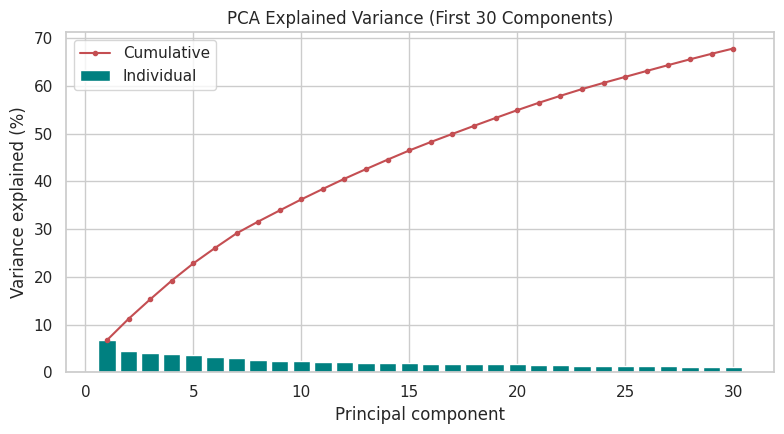

In [10]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X)
cum = np.cumsum(pca_full.explained_variance_ratio_)
for t in (0.5, 0.7, 0.9):
    print(f'Components needed for {t:.0%} variance: {np.argmax(cum >= t) + 1}')
print('Variance explained by PC1, PC2:', pca_full.explained_variance_ratio_[:2].round(4))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(range(1, 31), pca_full.explained_variance_ratio_[:30] * 100, color='teal', label='Individual')
ax.plot(range(1, 31), cum[:30] * 100, 'ro-', ms=3, label='Cumulative')
ax.set_title('PCA Explained Variance (First 30 Components)')
ax.set_xlabel('Principal component'); ax.set_ylabel('Variance explained (%)'); ax.legend()
save('cs1_pca_variance')

### A.10 What do the principal components represent?
**Observation:** the leading components are driven by the most popular products (mineral water, spaghetti, milk, chocolate, eggs, french fries). PCA is therefore mainly separating baskets by *which staple they contain*.

In [11]:
load = pd.DataFrame(pca_full.components_[:3].T, index=X.columns, columns=['PC1', 'PC2', 'PC3'])
for pc in load:
    print(pc, 'top loadings:', ', '.join(load[pc].abs().sort_values(ascending=False).head(5).index))

PC1 top loadings: mineral water, spaghetti, milk, chocolate, ground beef
PC2 top loadings: french fries, eggs, mineral water, chocolate, green tea
PC3 top loadings: eggs, spaghetti, mineral water, chocolate, ground beef


### A.11 Reducing to 10 components for clustering
**Purpose:** cluster in a 10-dimensional PCA space. This removes much of the noise from rare products and makes all four algorithms computationally practical, at the cost of keeping only 36.2% of the variance (a limitation discussed later).

In [12]:
N_COMP = 10
pca = PCA(n_components=N_COMP, random_state=RANDOM_STATE)
Z = pca.fit_transform(X)
print(f'{N_COMP} components retain {pca.explained_variance_ratio_.sum():.1%} of the variance')

10 components retain 36.2% of the variance


### A.12 Choosing the number of clusters
**Purpose:** run K-means for k = 2 to 10 and compare inertia (elbow), silhouette coefficient and Davies–Bouldin (DB) index.

**Interpretation:** inertia falls smoothly with no sharp elbow, so the elbow method is inconclusive. The silhouette keeps rising slowly with k (0.25 → 0.32), while the DB index reaches its minimum of 1.477 at **k = 7**. k = 7 is chosen because it gives the most compact, well-separated clusters by DB while still having a reasonable silhouette (0.291), and seven groups remain interpretable.

     inertia  silhouette  davies_bouldin
k                                       
2   8230.639       0.254           1.947
3   7371.837       0.251           1.791
4   6651.057       0.263           1.670
5   6122.923       0.268           1.560
6   5727.971       0.277           1.520
7   5375.170       0.291           1.477
8   5071.597       0.307           1.561
9   4820.925       0.311           1.535
10  4679.894       0.322           1.563


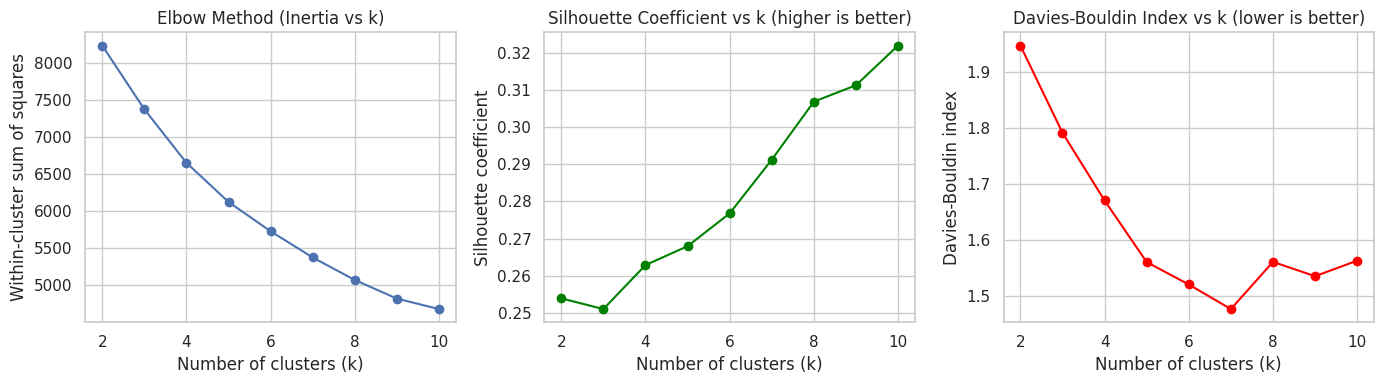

In [13]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    rows.append({'k': k, 'inertia': km.inertia_, 'silhouette': silhouette_score(Z, km.labels_),
                 'davies_bouldin': davies_bouldin_score(Z, km.labels_)})
ksel = pd.DataFrame(rows).set_index('k'); print(ksel.round(3))
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
axs[0].plot(ksel.index, ksel.inertia, 'o-'); axs[0].set_title('Elbow Method (Inertia vs k)'); axs[0].set_ylabel('Within-cluster sum of squares')
axs[1].plot(ksel.index, ksel.silhouette, 'o-', color='green'); axs[1].set_title('Silhouette Coefficient vs k (higher is better)'); axs[1].set_ylabel('Silhouette coefficient')
axs[2].plot(ksel.index, ksel.davies_bouldin, 'o-', color='red'); axs[2].set_title('Davies-Bouldin Index vs k (lower is better)'); axs[2].set_ylabel('Davies-Bouldin index')
for a in axs: a.set_xlabel('Number of clusters (k)')
save('cs1_k_selection')

### A.13 K-means clustering (k = 7)
**Purpose:** fit the final K-means model and record the cluster of every transaction.

In [14]:
K = int(ksel.davies_bouldin.idxmin())
print('Chosen k (lowest Davies-Bouldin):', K)
km_labels = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit_predict(Z)
print('Cluster sizes:', np.bincount(km_labels))

Chosen k (lowest Davies-Bouldin): 7
Cluster sizes: [ 872  732 2546  566  858 1113  814]


### A.14 Interpreting the K-means clusters
**Purpose:** for each cluster, compute the share of baskets containing each product, so the clusters can be described in business terms.

**Interpretation of the heatmap:** six clusters are each "anchored" by one staple present in 100% of their baskets: chocolate, eggs, green tea, mineral water, spaghetti and french fries. The spaghetti cluster has the largest baskets (6.45 items) and frequently also contains mineral water (40%) and ground beef (26%), which looks like a meal-preparation shop. The largest cluster (2,546 baskets, 2.12 items) contains *none* of these anchors and is a mixed group of small baskets of less common products.

   size  avg_items                                          defining_products
0   872       4.89  chocolate (100%), mineral water (32%), french fries (23%)
1   732       4.03            eggs (100%), mineral water (27%), burgers (14%)
2  2546       2.12                    cookies (13%), escalope (9%), milk (8%)
3   566       4.54              green tea (100%), chocolate (16%), eggs (16%)
4   858       4.45       mineral water (100%), milk (15%), french fries (13%)
5  1113       6.45   spaghetti (100%), mineral water (40%), ground beef (26%)
6   814       3.91           french fries (100%), eggs (22%), green tea (17%)


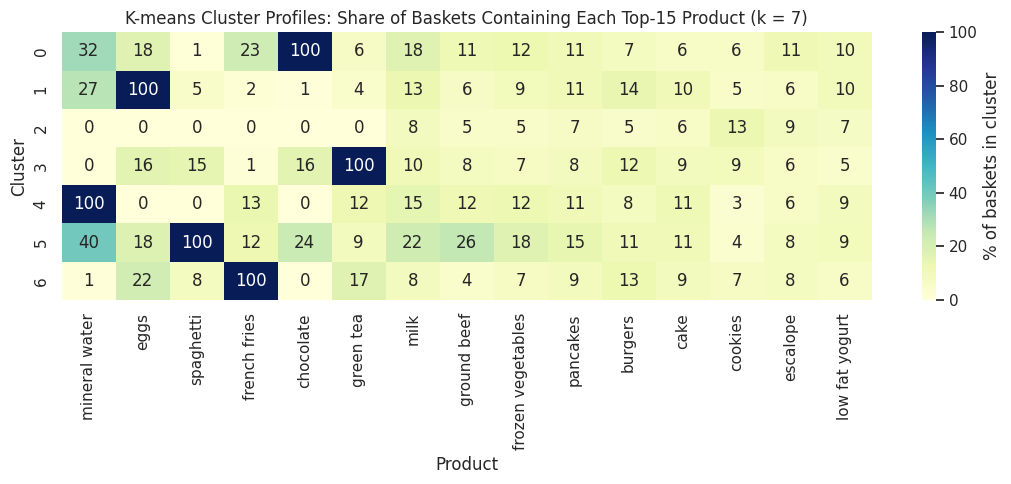

In [15]:
prof = X.groupby(km_labels).mean()
prof.index.name = 'cluster'
summary = pd.DataFrame({'size': np.bincount(km_labels), 'avg_items': tx['size'].groupby(km_labels).mean().round(2),
                        'defining_products': [', '.join(f'{p} ({v:.0%})' for p, v in prof.loc[c].sort_values(ascending=False).head(3).items()) for c in prof.index]})
print(summary.to_string())
topcols = support.head(15).index
plt.figure(figsize=(11, 5))
sns.heatmap(prof[topcols] * 100, annot=True, fmt='.0f', cmap='YlGnBu', cbar_kws={'label': '% of baskets in cluster'})
plt.title(f'K-means Cluster Profiles: Share of Baskets Containing Each Top-15 Product (k = {K})')
plt.xlabel('Product'); plt.ylabel('Cluster')
save('cs1_cluster_profiles')

### A.15 PCA visualisation of the clusters
**Interpretation:** in the PC1–PC2 plane several clusters form distinct bands. Each band corresponds to baskets containing a particular anchor product (e.g. the french-fries cluster at high PC2, the eggs cluster in a separate horizontal band), while the mixed small baskets sit at the low-PC1 end. Clusters overlap in two dimensions because only 11.2% of variance is shown here. Separation is better in the full 10-D space used for clustering.

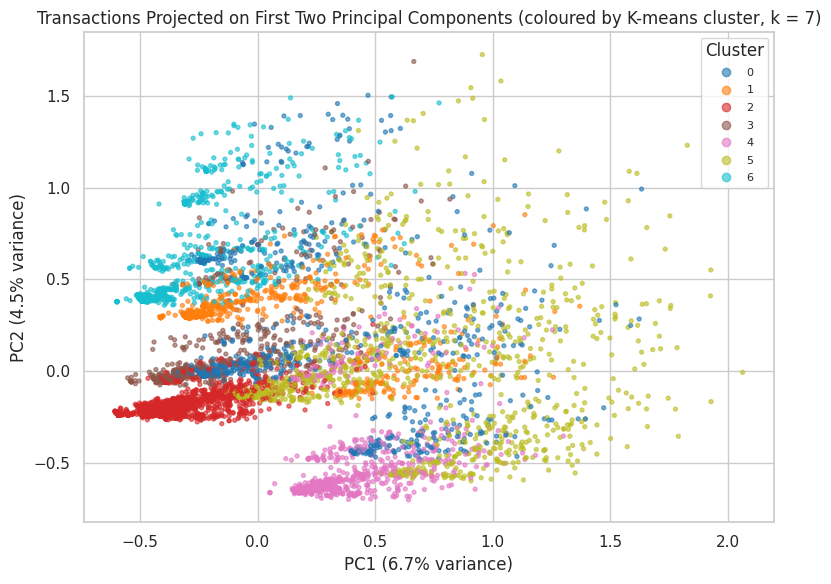

In [16]:
plt.figure(figsize=(8, 6))
sc = plt.scatter(Z[:, 0], Z[:, 1], c=km_labels, cmap='tab10', s=8, alpha=0.6)
plt.legend(*sc.legend_elements(), title='Cluster', loc='upper right', fontsize=8)
plt.title(f'Transactions Projected on First Two Principal Components (coloured by K-means cluster, k = {K})')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)'); plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
save('cs1_pca_kmeans_scatter')

### A.16 Hierarchical (agglomerative) clustering
**Purpose:** apply Ward-linkage agglomerative clustering with the same k = 7 for a fair comparison. Ward merges the pair of clusters that least increases within-cluster variance. The dendrogram is drawn on a random sample of 500 baskets because a full 7,501-leaf tree is unreadable.

**Interpretation:** the dendrogram shows several large merges at high linkage distance, consistent with a few broad groups. Ward's cluster sizes differ from K-means (two large groups of ~1,800–2,000), meaning it splits the mixed "no-anchor" baskets differently.

Hierarchical (Ward) cluster sizes: [1843  878  588  834  787 1979  592]


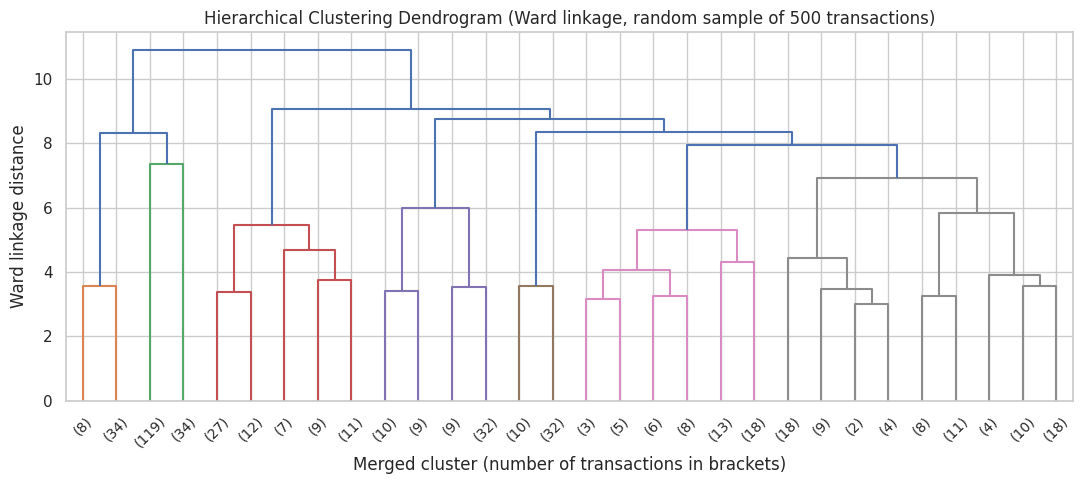

In [17]:
hc_labels = AgglomerativeClustering(n_clusters=K, linkage='ward').fit_predict(Z)
print('Hierarchical (Ward) cluster sizes:', np.bincount(hc_labels))
rng = np.random.default_rng(RANDOM_STATE); idx = rng.choice(len(Z), 500, replace=False)
plt.figure(figsize=(11, 5))
dendrogram(linkage(Z[idx], method='ward'), truncate_mode='lastp', p=30, color_threshold=None)
plt.title('Hierarchical Clustering Dendrogram (Ward linkage, random sample of 500 transactions)')
plt.xlabel('Merged cluster (number of transactions in brackets)'); plt.ylabel('Ward linkage distance')
save('cs1_dendrogram')

### A.17 DBSCAN: choosing eps
**Purpose:** DBSCAN groups points in dense regions and labels isolated points as noise. With `min_samples = 20`, the *k-distance graph* (distance to the 20th nearest neighbour, sorted) is used to pick `eps` at the point where distances begin to rise steeply.

**Interpretation:** most transactions have a 20th-neighbour distance below about 0.7, after which the curve bends upwards, so eps = 0.7 is used. The sensitivity table shows why this matters: eps = 0.9 merges almost everything into one cluster, while 0.5 marks more points as noise.

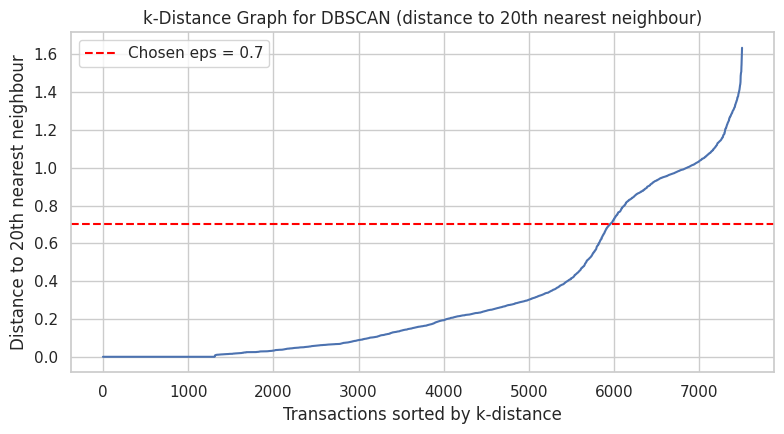

   eps  clusters  noise_points
0  0.5        36          1628
1  0.7        33          1118
2  0.9         1           539


In [18]:
MIN_SAMPLES = 20
kd = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Z).kneighbors(Z)[0][:, -1])
plt.figure(figsize=(8, 4.5))
plt.plot(kd); plt.axhline(0.7, color='red', ls='--', label='Chosen eps = 0.7')
plt.title(f'k-Distance Graph for DBSCAN (distance to {MIN_SAMPLES}th nearest neighbour)')
plt.xlabel('Transactions sorted by k-distance'); plt.ylabel(f'Distance to {MIN_SAMPLES}th nearest neighbour'); plt.legend()
save('cs1_dbscan_kdistance')
rows = []
for eps in (0.5, 0.7, 0.9):
    l = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(Z)
    rows.append({'eps': eps, 'clusters': len(set(l)) - (-1 in l), 'noise_points': int((l == -1).sum())})
print(pd.DataFrame(rows))

### A.18 DBSCAN results
**Observation:** DBSCAN finds 33 clusters and marks 1,118 baskets (14.9%) as noise. Many of its clusters are tight groups of near-identical small baskets (the dataset contains many exact repeats). One very large cluster gathers the small, mixed baskets. DBSCAN therefore finds *dense pockets of identical behaviour*, not broad shopping segments.

In [19]:
EPS = 0.7
db_labels = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(Z)
core = db_labels != -1
print(f'DBSCAN: {len(set(db_labels[core]))} clusters, {(~core).sum()} noise points ({(~core).mean():.1%})')
big = pd.Series(db_labels[core]).value_counts().head(5)
for c in big.index:
    m = db_labels == c
    print(f'  cluster {c}: {m.sum()} baskets, unique basket contents = {tx.loc[m, "items"].map(tuple).nunique()}, e.g. {tx.loc[m, "items"].iloc[0]}')

DBSCAN: 33 clusters, 1118 noise points (14.9%)
  cluster 1: 2528 baskets, unique basket contents = 1255, e.g. ['chutney']
  cluster 5: 564 baskets, unique basket contents = 389, e.g. ['mineral water', 'salmon']
  cluster 2: 457 baskets, unique basket contents = 234, e.g. ['french fries', 'whole wheat pasta']
  cluster 0: 426 baskets, unique basket contents = 238, e.g. ['burgers', 'eggs', 'meatballs']
  cluster 4: 366 baskets, unique basket contents = 276, e.g. ['champagne', 'cookies', 'spaghetti']


### A.19 Spectral clustering
**Purpose:** spectral clustering builds a 30-nearest-neighbour similarity graph, embeds it using the graph's eigenvectors and then partitions it into k = 7 groups. It can find non-convex clusters that K-means cannot.

**Observation:** one huge cluster (4,144 baskets) and several small ones are produced. On this data the neighbour graph is dominated by the dense centre, so spectral clustering does not split it well.

In [20]:
sp_labels = SpectralClustering(n_clusters=K, affinity='nearest_neighbors', n_neighbors=30,
                               assign_labels='cluster_qr', random_state=RANDOM_STATE).fit_predict(Z)
print('Spectral cluster sizes:', np.bincount(sp_labels))

Spectral cluster sizes: [ 449  298  467  439  472 1232 4144]


### A.20 Comparing clustering performance
**Purpose:** compute the silhouette coefficient (−1 to 1, higher = points closer to their own cluster than to others) and the Davies–Bouldin index (≥ 0, lower = more compact, better-separated clusters) for every algorithm on the same 10-D PCA features.

**Interpretation:**
- **K-means** gives the best scores among the methods that assign every basket (silhouette 0.291, DB 1.477).
- **Hierarchical (Ward)** is weaker (0.212 / 1.988) and **Spectral** is weakest (0.058 / 1.964). Spectral's silhouette near zero means its clusters overlap heavily.
- **DBSCAN** appears best (0.528 / 0.787), but this is **not a like-for-like comparison**: its scores ignore the 14.9% of baskets labelled as noise, and its 33 clusters are largely groups of identical baskets, which are trivially compact.
- All silhouettes are well below 0.5, so even the best partition represents *weak* structure. Shopping baskets in this data overlap substantially.

                         Clusters  Points scored  Silhouette  Davies-Bouldin
Algorithm                                                                   
K-means                         7           7501       0.291           1.477
Hierarchical (Ward)             7           7501       0.212           1.988
DBSCAN (noise excluded)        33           6383       0.528           0.787
Spectral                        7           7501       0.058           1.964


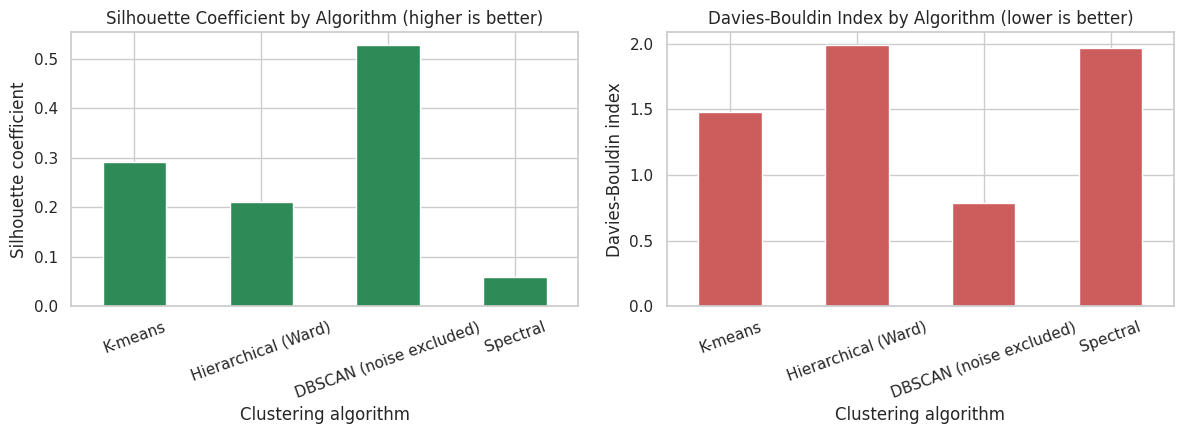

In [21]:
def scores(name, lab, mask=None):
    m = np.ones(len(lab), bool) if mask is None else mask
    return {'Algorithm': name, 'Clusters': len(set(lab[m])), 'Points scored': int(m.sum()),
            'Silhouette': silhouette_score(Z[m], lab[m]), 'Davies-Bouldin': davies_bouldin_score(Z[m], lab[m])}
comp = pd.DataFrame([scores('K-means', km_labels), scores('Hierarchical (Ward)', hc_labels),
                     scores('DBSCAN (noise excluded)', db_labels, core), scores('Spectral', sp_labels)]).set_index('Algorithm')
print(comp.round(3))
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
comp['Silhouette'].plot.bar(ax=axs[0], color='seagreen'); axs[0].set_title('Silhouette Coefficient by Algorithm (higher is better)'); axs[0].set_ylabel('Silhouette coefficient')
comp['Davies-Bouldin'].plot.bar(ax=axs[1], color='indianred'); axs[1].set_title('Davies-Bouldin Index by Algorithm (lower is better)'); axs[1].set_ylabel('Davies-Bouldin index')
for a in axs: a.set_xlabel('Clustering algorithm'); a.tick_params(axis='x', rotation=20)
save('cs1_algorithm_comparison')

### A.21 Agreement between algorithms
**Purpose:** the Adjusted Rand Index (ARI) measures how similar two partitions are (1 = identical, 0 = no better than chance).

**Observation:** Ward agrees moderately with K-means (ARI 0.504), so the anchor-product groups are partly stable across methods. Spectral agrees poorly (0.148). The structure that is robust is the separation of baskets by their dominant staple product.

In [22]:
from sklearn.metrics import adjusted_rand_score
print('Agreement with K-means (Adjusted Rand Index):')
print('  Hierarchical:', round(adjusted_rand_score(km_labels, hc_labels), 3))
print('  Spectral    :', round(adjusted_rand_score(km_labels, sp_labels), 3))

Agreement with K-means (Adjusted Rand Index):
  Hierarchical: 0.504
  Spectral    : 0.148


### A.22 Limitations and business implications
**Limitations**
1. The binary encoding ignores quantity, price and time; two baskets are "similar" only if they share products.
2. Only 36.2% of variance is kept in 10 PCA components, so some information about rare products is discarded.
3. The low silhouette scores (< 0.33) show weak natural cluster structure; the clusters are useful summaries, not sharply distinct customer types.
4. Clusters describe *transactions*, not customers. There is no customer ID, so repeat behaviour cannot be analysed.
5. Results depend on choices of k, eps and neighbourhood size, and Euclidean distance on PCA scores is only one possible similarity measure (Jaccard distance is a common alternative for baskets).

**Business implications**
- Six anchor-product segments (mineral water, eggs, spaghetti, french fries, chocolate, green tea) suggest these staples drive store visits; they are natural candidates for placement near complementary items.
- The spaghetti segment has the largest baskets and often includes ground beef and mineral water, which supports meal-bundle promotions.
- Nearly a quarter of baskets contain a single item, so prompts for add-on purchases could raise basket size.
- Association-rule mining (Apriori) would be a natural next step to quantify which product pairs are bought together.

---
# Part B — Case Study 4: Predicting Student Dropout and Academic Success
**Problem statement:** a higher-education institution wants to understand factors associated with dropout and academic success, and to predict whether a student's eventual outcome is *Dropout*, *Enrolled* or *Graduate*, using demographic, admission, socioeconomic and academic data. Because the target is the status at the end of the normal course duration, the model must use only variables available at the time of an early prediction.

### B.0 Setup
**Purpose:** import Pandas, SciPy (hypothesis tests), Scikit-learn (encoding, scaling, logistic regression, metrics) and plotting libraries; fix the class order *Dropout, Enrolled, Graduate* and a colour for each outcome so every chart is consistent.

In [23]:
import warnings; warnings.filterwarnings('ignore')
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, balanced_accuracy_score)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid'); os.makedirs('figures', exist_ok=True)
RANDOM_STATE = 42; ORDER = ['Dropout', 'Enrolled', 'Graduate']
PAL = {'Dropout': '#d62728', 'Enrolled': '#ff7f0e', 'Graduate': '#2ca02c'}
def save(name): plt.tight_layout(); plt.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight'); plt.show()

## Part A — Data understanding and preprocessing
### B.1 Loading the dataset and first five records
**Purpose:** the file is **semicolon-separated** (UCI format), so `sep=';'` is required. One column name contains a hidden tab character (`Daytime/evening attendance\t`) and the original spelling *Nacionality* is corrected to *Nationality*.

**Observation:** 4,424 students and 37 columns.

In [24]:
df = pd.read_csv('Studentdata.csv', sep=';')
df.columns = df.columns.str.strip().str.replace('Nacionality', 'Nationality')
print('Rows, columns:', df.shape)
df.head()

Rows, columns: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nationality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


### B.2 Data types
**Observation:** 29 integer columns, 7 float columns and 1 text column (the target). Integer type does **not** mean numerical meaning: many integer columns are codes for categories (e.g. Course = 9254).

In [25]:
print(df.dtypes.value_counts()); df.dtypes.to_frame('dtype').T

int64      29
float64     7
str         1
Name: count, dtype: int64


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nationality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
dtype,int64,int64,int64,int64,int64,int64,float64,int64,int64,int64,int64,int64,float64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,float64,int64,int64,int64,int64,int64,float64,int64,float64,float64,float64,str


### B.3 Target and predictor variables
**Observation:** the target is `Target`, with three classes (Dropout, Enrolled, Graduate), recording the student's status at the end of the normal course duration. All other 36 columns are candidate predictors.

In [26]:
TARGET = 'Target'
predictors = [c for c in df.columns if c != TARGET]
print('Target variable :', TARGET, '->', sorted(df[TARGET].unique()))
print('Predictor count :', len(predictors))

Target variable : Target -> ['Dropout', 'Enrolled', 'Graduate']
Predictor count : 36


### B.4 Categorising the attributes by meaning
**Purpose:** classify each attribute by what its encoded values *mean*, not by its stored data type.
- **Categorical (nominal):** marital status, application mode, course, previous qualification, nationality and parents' qualifications/occupations. Their numbers are labels, so "Course 9254 > Course 171" is meaningless. These must be one-hot encoded.
- **Binary:** 0/1 flags such as Debtor, Scholarship holder, Tuition fees up to date, Gender.
- **Numerical:** grades, age, counts of curricular units, application order (ordinal 0–9) and the macro-economic indicators.

In [27]:
categorical = ['Marital status', 'Application mode', 'Course', 'Previous qualification', 'Nationality',
               "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
binary = ['Daytime/evening attendance', 'Displaced', 'Educational special needs', 'Debtor',
          'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']
numerical = [c for c in predictors if c not in categorical + binary]
attr = pd.DataFrame({'Attribute type': ['Categorical (nominal code)'] * len(categorical) + ['Binary (0/1)'] * len(binary) + ['Numerical'] * len(numerical),
                     'Distinct values': [df[c].nunique() for c in categorical + binary + numerical]}, index=categorical + binary + numerical)
print(attr.to_string())

                                                            Attribute type  Distinct values
Marital status                                  Categorical (nominal code)                6
Application mode                                Categorical (nominal code)               18
Course                                          Categorical (nominal code)               17
Previous qualification                          Categorical (nominal code)               17
Nationality                                     Categorical (nominal code)               21
Mother's qualification                          Categorical (nominal code)               29
Father's qualification                          Categorical (nominal code)               34
Mother's occupation                             Categorical (nominal code)               32
Father's occupation                             Categorical (nominal code)               46
Daytime/evening attendance                                    Binary (0/1)      

### B.5 Missing values, duplicates and unusual values
**Observation:**
- No missing values and no duplicate records.
- **718 students have a first-semester grade of 0.** All 718 approved zero units, and 180 of them were not enrolled in any units. Since grades are on a 0–20 scale with 10 as the pass mark, a 0 means "no grade obtained", not an actual mark of zero. These records are kept because they are highly informative (see B.11), but the hypothesis test is also repeated without them.
- Age ranges from 17 to 70; 441 students are IQR outliers (older than ~34) and 225 are over 40. These are plausible mature students, not errors, so they are kept.
- Admission grade lies within its valid 95–190 range.

In [28]:
print('Missing values (total):', df.isna().sum().sum())
print('Duplicate records     :', df.duplicated().sum())
g1 = 'Curricular units 1st sem (grade)'
print('Students with 1st-sem grade = 0          :', (df[g1] == 0).sum())
print('  ...of which enrolled in 0 units in sem 1:', ((df[g1] == 0) & (df['Curricular units 1st sem (enrolled)'] == 0)).sum())
print('  ...of which approved 0 units in sem 1   :', ((df[g1] == 0) & (df['Curricular units 1st sem (approved)'] == 0)).sum())
print('Age at enrollment range:', df['Age at enrollment'].min(), '-', df['Age at enrollment'].max(), '| students aged > 40:', (df['Age at enrollment'] > 40).sum())
print('Admission grade range  :', df['Admission grade'].min(), '-', df['Admission grade'].max())
q1, q3 = df['Age at enrollment'].quantile([.25, .75]); print('IQR outliers in age:', (df['Age at enrollment'] > q3 + 1.5 * (q3 - q1)).sum())

Missing values (total): 0
Duplicate records     : 0
Students with 1st-sem grade = 0          : 718
  ...of which enrolled in 0 units in sem 1: 180
  ...of which approved 0 units in sem 1   : 718
Age at enrollment range: 17 - 70 | students aged > 40: 225
Admission grade range  : 95.0 - 190.0
IQR outliers in age: 441


### B.6 Distributions of selected numerical attributes
**Interpretation of the histograms:**
- **Age at enrollment** is strongly right-skewed (skew 2.05): most students start at 18–20, with a long tail of mature students.
- **Admission grade** and **previous qualification grade** are roughly bell-shaped around 125–135.
- **First-semester grade** is left-skewed (skew −1.57) and bimodal: most students score 11–14, but there is a separate spike at 0 (the 718 students with no grade).

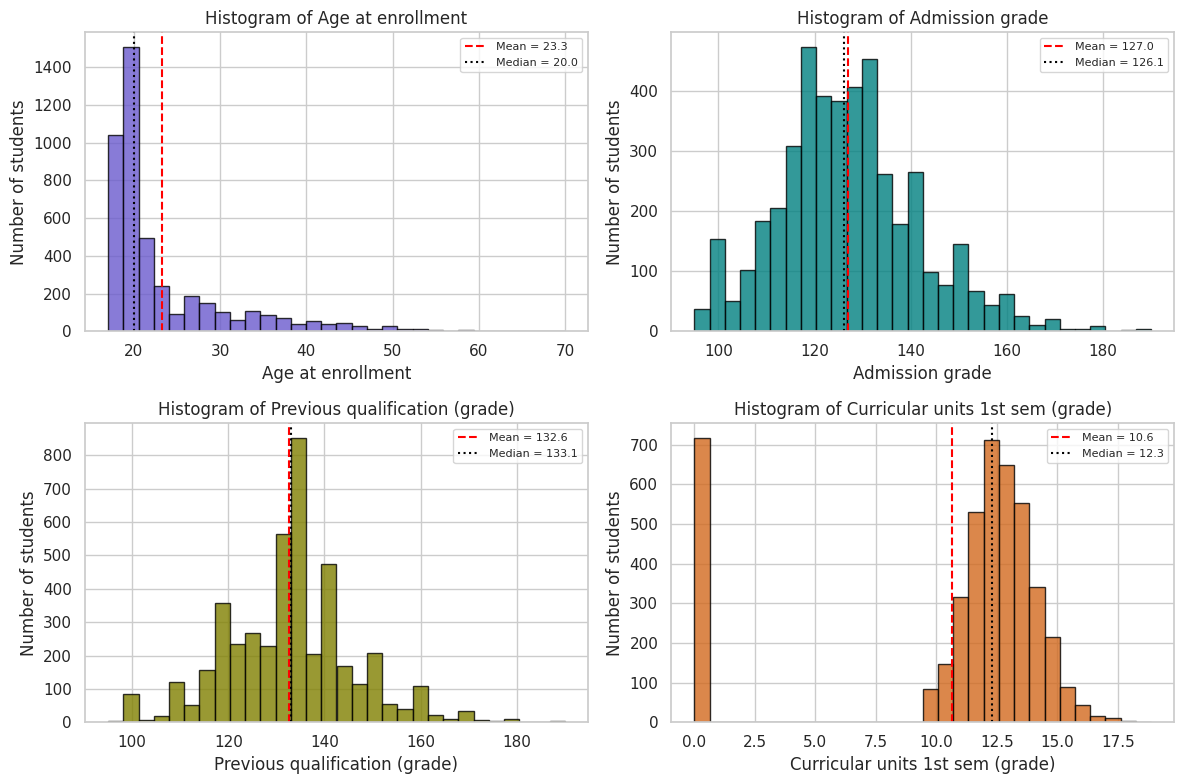

      Age at enrollment  Admission grade  Previous qualification (grade)  Curricular units 1st sem (grade)
skew               2.05             0.53                            0.31                             -1.57


In [29]:
sel = ['Age at enrollment', 'Admission grade', 'Previous qualification (grade)', g1]
fig, axs = plt.subplots(2, 2, figsize=(12, 8))
for ax, c, col in zip(axs.ravel(), sel, ['slateblue', 'teal', 'olive', 'chocolate']):
    ax.hist(df[c], bins=30, color=col, edgecolor='black', alpha=.8)
    ax.axvline(df[c].mean(), color='red', ls='--', label=f'Mean = {df[c].mean():.1f}')
    ax.axvline(df[c].median(), color='black', ls=':', label=f'Median = {df[c].median():.1f}')
    ax.set_title(f'Histogram of {c}'); ax.set_xlabel(c); ax.set_ylabel('Number of students'); ax.legend(fontsize=8)
save('cs4_histograms')
print(df[sel].agg(['skew']).round(2))

### B.7 Preprocessing required before modelling
Based on B.4–B.6, the following steps are necessary:
1. **Encode categorical codes** with one-hot encoding (rare categories with fewer than 10 students are grouped) so the model does not treat codes as quantities.
2. **Scale numerical features** with `StandardScaler`; logistic regression with regularisation is sensitive to feature scale, and scaling makes coefficients comparable.
3. **Exclude 2nd-semester variables** for an *early-warning* model, because they are not available when an early prediction would be made (avoids look-ahead leakage).
4. **Stratified train/test split** to keep the imbalanced class proportions equal in both sets.
5. **Fit preprocessing on training data only** (inside a Pipeline) to prevent test-set information leaking into scaling.

## Part B — Exploratory data analysis and statistics
### B.8 Target-class distribution
**Interpretation:** about half the students graduate (49.9%), almost one third drop out (32.1%) and 17.9% are still enrolled. The classes are **imbalanced**: Enrolled is the minority, with less than half the size of Graduate. A model that always predicted "Graduate" would already be about 50% accurate, which is why accuracy alone is not enough.

          Students  Percentage
Target                        
Dropout       1421       32.12
Enrolled       794       17.95
Graduate      2209       49.93


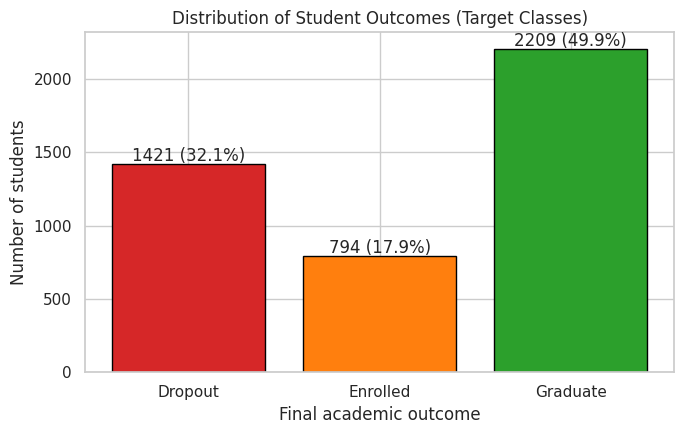

In [30]:
counts = df[TARGET].value_counts().reindex(ORDER)
dist = pd.DataFrame({'Students': counts, 'Percentage': (counts / len(df) * 100).round(2)}); print(dist)
plt.figure(figsize=(7, 4.5))
bars = plt.bar(ORDER, counts, color=[PAL[o] for o in ORDER], edgecolor='black')
for b, p in zip(bars, dist.Percentage): plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 20, f'{b.get_height()} ({p:.1f}%)', ha='center')
plt.title('Distribution of Student Outcomes (Target Classes)'); plt.xlabel('Final academic outcome'); plt.ylabel('Number of students')
save('cs4_target_distribution')

### B.9 Descriptive statistics
**Observation:** dropouts are older on average (26.1 vs 21.8 years for graduates) and approve far fewer first-semester units (2.55 vs 6.23). Their mean first-semester grade (7.26) is much lower than graduates' (12.64). Admission grades differ only slightly (125.0 vs 128.8).

In [31]:
desc_cols = ['Age at enrollment', 'Admission grade', 'Previous qualification (grade)', g1, 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (enrolled)']
print(df[desc_cols].describe().T.round(2))
print('\nMean by outcome:'); print(df.groupby(TARGET)[desc_cols].mean().reindex(ORDER).T.round(2))

                                      count    mean    std   min    25%     50%    75%     max
Age at enrollment                    4424.0   23.27   7.59  17.0   19.0   20.00   25.0   70.00
Admission grade                      4424.0  126.98  14.48  95.0  117.9  126.10  134.8  190.00
Previous qualification (grade)       4424.0  132.61  13.19  95.0  125.0  133.10  140.0  190.00
Curricular units 1st sem (grade)     4424.0   10.64   4.84   0.0   11.0   12.29   13.4   18.88
Curricular units 1st sem (approved)  4424.0    4.71   3.09   0.0    3.0    5.00    6.0   26.00
Curricular units 1st sem (enrolled)  4424.0    6.27   2.48   0.0    5.0    6.00    7.0   26.00

Mean by outcome:
Target                               Dropout  Enrolled  Graduate
Age at enrollment                      26.07     22.37     21.78
Admission grade                       124.96    125.53    128.79
Previous qualification (grade)        131.11    131.21    134.08
Curricular units 1st sem (grade)        7.26     11.13   

### B.10 Do admission grades differ across outcomes?
**Interpretation of the box plot:** graduates have a slightly higher median admission grade (127.4) than dropouts (123.6) and enrolled students (124.1), but the boxes overlap almost completely.

A Kruskal–Wallis test gives p ≈ 1.3 × 10⁻¹⁶, so the difference is statistically significant. However, the effect size ε² = 0.016 means outcome explains under 2% of the variation in admission ranks. **The difference is real but of little practical importance**: admission grade alone is a weak indicator of who will drop out.

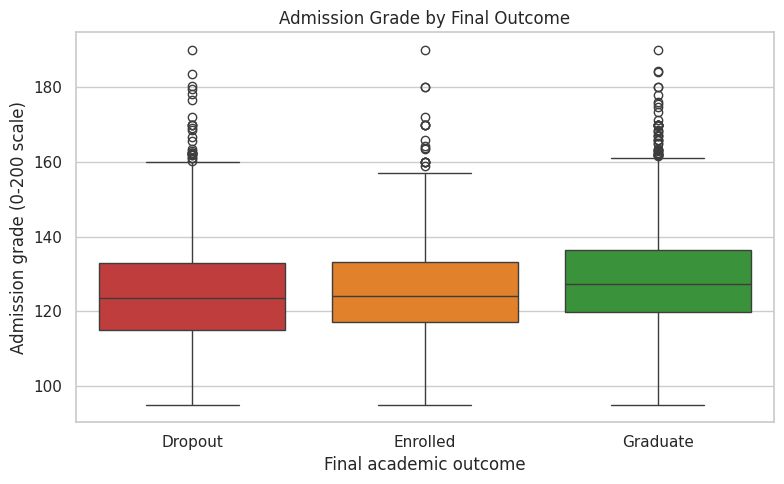

            mean  median    std
Target                         
Dropout   124.96   123.6  15.13
Enrolled  125.53   124.1  13.79
Graduate  128.79   127.4  14.07
Kruskal-Wallis on admission grade: H = 73.23, p = 1.25e-16, epsilon^2 = 0.016


In [32]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x=TARGET, y='Admission grade', order=ORDER, palette=PAL)
plt.title('Admission Grade by Final Outcome'); plt.xlabel('Final academic outcome'); plt.ylabel('Admission grade (0-200 scale)')
save('cs4_admission_boxplot')
print(df.groupby(TARGET)['Admission grade'].agg(['mean', 'median', 'std']).reindex(ORDER).round(2))
h, p = stats.kruskal(*[df.loc[df[TARGET] == o, 'Admission grade'] for o in ORDER])
print(f'Kruskal-Wallis on admission grade: H = {h:.2f}, p = {p:.2e}, epsilon^2 = {(h - 3 + 1) / (len(df) - 3):.3f}')

### B.11 First-semester performance and final outcome
**Interpretation:**
- *Violin plot (left):* graduates' grades are concentrated around 12–14. Dropouts show two groups: a large mass at 0 and another around 11–12.
- *Stacked bar (right):* the dropout share falls sharply as more units are approved. **79.4% of students who approved no first-semester units dropped out, compared with 10.2% of those who approved six or more.**

First-semester academic progress is the clearest early signal of eventual outcome in this dataset.

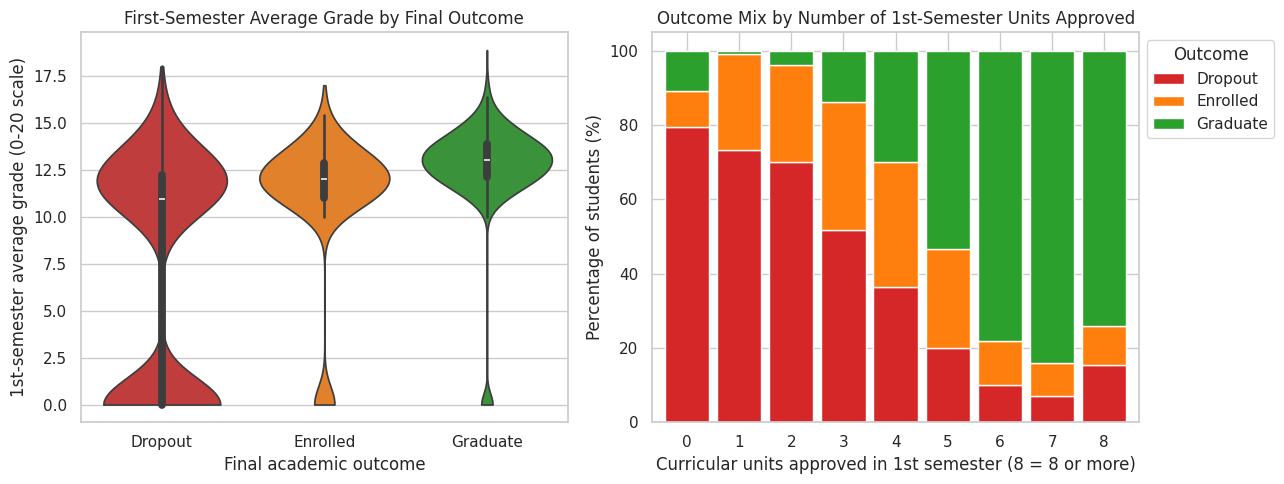

           mean  median   std  % with grade 0
Target                                       
Dropout    7.26   10.93  6.03           40.11
Enrolled  11.13   12.00  3.68            8.94
Graduate  12.64   13.00  2.70            3.49

Dropout rate when 0 units approved in sem 1: 79.4%
Dropout rate when 6+ units approved in sem 1: 10.2%


In [33]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
sns.violinplot(data=df, x=TARGET, y=g1, order=ORDER, palette=PAL, cut=0, ax=axs[0])
axs[0].set_title('First-Semester Average Grade by Final Outcome'); axs[0].set_xlabel('Final academic outcome'); axs[0].set_ylabel('1st-semester average grade (0-20 scale)')
appr = pd.crosstab(df['Curricular units 1st sem (approved)'].clip(upper=8), df[TARGET], normalize='index')[ORDER] * 100
appr.plot.bar(stacked=True, color=[PAL[o] for o in ORDER], ax=axs[1], width=.85)
axs[1].set_title('Outcome Mix by Number of 1st-Semester Units Approved'); axs[1].set_xlabel('Curricular units approved in 1st semester (8 = 8 or more)'); axs[1].set_ylabel('Percentage of students (%)')
axs[1].legend(title='Outcome', bbox_to_anchor=(1, 1)); axs[1].tick_params(axis='x', rotation=0)
save('cs4_sem1_vs_outcome')
print(df.groupby(TARGET)[g1].agg(['mean', 'median', 'std', lambda s: (s == 0).mean() * 100]).rename(columns={'<lambda_0>': '% with grade 0'}).reindex(ORDER).round(2))
print('\nDropout rate when 0 units approved in sem 1: {:.1%}'.format((df.loc[df['Curricular units 1st sem (approved)'] == 0, TARGET] == 'Dropout').mean()))
print('Dropout rate when 6+ units approved in sem 1: {:.1%}'.format((df.loc[df['Curricular units 1st sem (approved)'] >= 6, TARGET] == 'Dropout').mean()))

### B.12 Is age at enrollment associated with outcome?
**Interpretation:** the outcome mix changes clearly with age. Among students who enrolled at 17–20, 60.3% graduate and 21.2% drop out; for those aged 25–29, the dropout share rises to 57.6%. A chi-square test of independence (χ² = 458.7, df = 8, p < 0.001, Cramér's V = 0.228) confirms a significant, moderate association.

This is an association only. Older students often study part-time while working or caring for family, and those circumstances, rather than age itself, may explain the pattern.

Target     Dropout  Enrolled  Graduate  Total
Age group                                    
17-20          542       471      1538   2551
21-24          248       161       326    735
25-29          246        72       109    427
30-39          258        60       145    463
40+            127        30        91    248
Target     Dropout  Enrolled  Graduate
Age group                             
17-20         21.2      18.5      60.3
21-24         33.7      21.9      44.4
25-29         57.6      16.9      25.5
30-39         55.7      13.0      31.3
40+           51.2      12.1      36.7


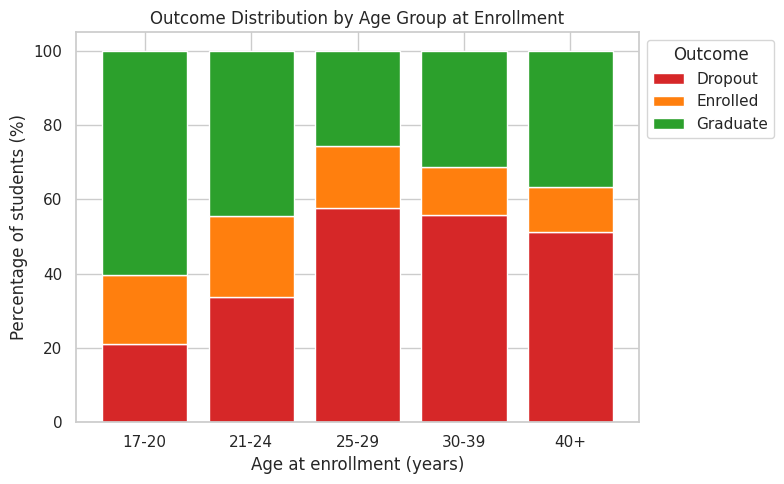

Chi-square test: chi2 = 458.71, dof = 8, p = 5.02e-94, Cramer's V = 0.228


In [34]:
df['Age group'] = pd.cut(df['Age at enrollment'], [16, 20, 24, 29, 39, 100], labels=['17-20', '21-24', '25-29', '30-39', '40+'])
ct = pd.crosstab(df['Age group'], df[TARGET])[ORDER]
pct = (ct.div(ct.sum(1), axis=0) * 100).round(1); print(ct.assign(Total=ct.sum(1))); print(pct)
pct.plot.bar(stacked=True, color=[PAL[o] for o in ORDER], figsize=(8, 5), width=.8)
plt.title('Outcome Distribution by Age Group at Enrollment'); plt.xlabel('Age at enrollment (years)'); plt.ylabel('Percentage of students (%)')
plt.legend(title='Outcome', bbox_to_anchor=(1, 1)); plt.xticks(rotation=0)
save('cs4_age_outcome')
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(f"Chi-square test: chi2 = {chi2:.2f}, dof = {dof}, p = {p:.2e}, Cramer's V = {np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))):.3f}")

### B.13 An additional finding: tuition-fee status
**Observation:** 86.6% of students whose fees were not up to date dropped out, compared with 24.7% of those whose fees were up to date. Financial difficulty is strongly associated with dropout. Because the timing of this variable is not documented, it may partly *reflect* the decision to leave rather than precede it.

In [35]:
fee = pd.crosstab(df['Tuition fees up to date'].map({0: 'Not up to date', 1: 'Up to date'}), df[TARGET], normalize='index')[ORDER] * 100
print(fee.round(1))

Target                   Dropout  Enrolled  Graduate
Tuition fees up to date                             
Not up to date              86.6       8.0       5.5
Up to date                  24.7      19.3      56.0


## Part C — Hypothesis testing
**Research question:** do first-semester average grades differ between Dropout, Enrolled and Graduate students?

- **H₀:** the distribution of first-semester grades is the same in all three outcome groups.
- **H₁:** at least one outcome group has a different distribution (tends to have higher or lower grades).
- **Significance level:** α = 0.05.

### B.14 Choosing the test and checking assumptions
One-way ANOVA would compare means but assumes normal data in each group and equal variances. These assumptions are checked:

**Observation:** all three groups fail the normality test (p < 0.001); the Q-Q plots bend sharply away from the line because of the spike at zero. Levene's test shows very unequal variances (W = 549.9, p < 0.001); the dropout group's SD is 6.0 versus 2.7 for graduates. **ANOVA's assumptions are not reasonable here**, so the non-parametric **Kruskal–Wallis H test** is selected.

Kruskal–Wallis assumptions: independent observations (each student appears once), an ordinal or continuous outcome, and three independent groups. All are satisfied.

Dropout   n = 1421  skew = -0.31  D'Agostino normality p = 0.0e+00
Enrolled  n =  794  skew = -2.36  D'Agostino normality p = 6.2e-83
Graduate  n = 2209  skew = -3.45  D'Agostino normality p = 0.0e+00
Levene test for equal variances: W = 549.87, p = 5.5e-214


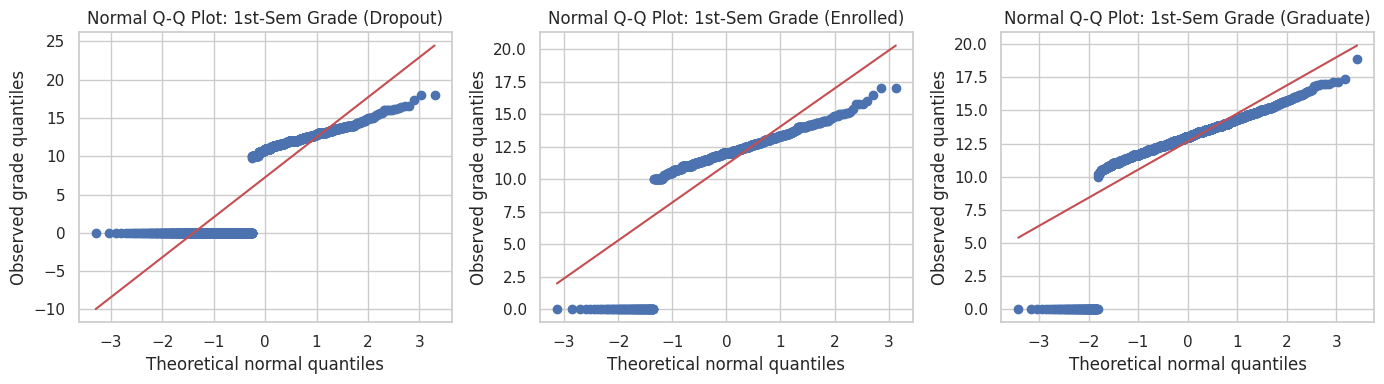

In [36]:
groups = [df.loc[df[TARGET] == o, g1] for o in ORDER]
for o, g in zip(ORDER, groups):
    print(f'{o:9s} n = {len(g):4d}  skew = {g.skew():5.2f}  D\'Agostino normality p = {stats.normaltest(g).pvalue:.1e}')
lev = stats.levene(*groups); print(f'Levene test for equal variances: W = {lev.statistic:.2f}, p = {lev.pvalue:.1e}')
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, o, g in zip(axs, ORDER, groups):
    stats.probplot(g, dist='norm', plot=ax); ax.set_title(f'Normal Q-Q Plot: 1st-Sem Grade ({o})')
    ax.set_xlabel('Theoretical normal quantiles'); ax.set_ylabel('Observed grade quantiles')
save('cs4_qq_plots')

### B.15 Performing the Kruskal–Wallis test
**Result:** H = 1094.19, df = 2, p ≈ 2.5 × 10⁻²³⁸.

**Conclusion:** since p < 0.05, **H₀ is rejected**. There is very strong evidence that first-semester grades differ between students who drop out, remain enrolled or graduate.

**Statistical vs practical significance:** with 4,424 students, even tiny differences can be significant, so the effect size matters. ε² = 0.247 means about a quarter of the variation in grade ranks is associated with outcome. That is a **large** effect, so here the difference is both statistically significant *and* practically important. ANOVA, shown for reference only, reaches the same conclusion.

In [37]:
H, p_kw = stats.kruskal(*groups)
eps2 = (H - len(groups) + 1) / (len(df) - len(groups))
print(f'Kruskal-Wallis H = {H:.2f}, df = {len(groups) - 1}, p-value = {p_kw:.3e}')
print(f'Effect size epsilon-squared = {eps2:.3f}')
print('Decision at alpha = 0.05:', 'Reject H0' if p_kw < 0.05 else 'Fail to reject H0')
F, p_w = stats.f_oneway(*groups); print(f'(Reference) one-way ANOVA F = {F:.2f}, p = {p_w:.3e}')

Kruskal-Wallis H = 1094.19, df = 2, p-value = 2.514e-238
Effect size epsilon-squared = 0.247
Decision at alpha = 0.05: Reject H0
(Reference) one-way ANOVA F = 713.52, p = 2.803e-269


### B.16 Which groups differ? (post-hoc test)
**Purpose:** Kruskal–Wallis only says *some* groups differ. Pairwise Mann–Whitney U tests with a Bonferroni correction (p × 3) identify which.

**Observation:** all three pairs differ significantly (adjusted p < 0.001). The largest separation is Dropout vs Graduate (median difference ≈ 2.1 grade points, rank-biserial r = 0.62, a large effect). Enrolled students sit in between.

In [38]:
from itertools import combinations
pairs = []
for a, b in combinations(ORDER, 2):
    x, y = df.loc[df[TARGET] == a, g1], df.loc[df[TARGET] == b, g1]
    U, p = stats.mannwhitneyu(x, y)
    pairs.append({'Comparison': f'{a} vs {b}', 'U': U, 'p (Bonferroni)': min(p * 3, 1), 'Median diff': y.median() - x.median(),
                  'Rank-biserial r': 1 - 2 * U / (len(x) * len(y))})
print(pd.DataFrame(pairs).round(4).to_string(index=False))

          Comparison        U  p (Bonferroni)  Median diff  Rank-biserial r
 Dropout vs Enrolled 368443.5             0.0       1.0714           0.3469
 Dropout vs Graduate 600098.0             0.0       2.0714           0.6176
Enrolled vs Graduate 524677.0             0.0       1.0000           0.4017


### B.17 Sensitivity check: excluding students with no grade
**Observation:** removing the 718 zero grades, the test is still highly significant (p ≈ 10⁻¹⁰⁴), but the effect size halves (ε² = 0.128) and the medians are close: 12.0 (Dropout), 12.1 (Enrolled), 13.0 (Graduate). Much of the original effect comes from students who obtained **no** grade at all. Failing to engage with assessments is an even stronger signal than a low grade.

In [39]:
nz = [g[g > 0] for g in groups]
Hn, pn = stats.kruskal(*nz); print(f'Excluding grade = 0: H = {Hn:.2f}, p = {pn:.2e}, epsilon^2 = {(Hn - 2) / (sum(map(len, nz)) - 3):.3f}')
print('Medians (grade > 0):', [round(g.median(), 2) for g in nz])

Excluding grade = 0: H = 474.47, p = 9.34e-104, epsilon^2 = 0.128
Medians (grade > 0): [np.float64(12.0), np.float64(12.12), np.float64(13.02)]


## Part D — Classification model
### B.18 Separating predictors and target; choosing early-prediction features
**Purpose:** the target is the status at the *end* of the course, but a useful support system must predict early. All six **2nd-semester variables are excluded** because they would not exist at the end of semester 1; including them would inflate performance unrealistically. The model uses the 30 remaining variables: admission-time information, socioeconomic and macro-economic indicators, and 1st-semester results.

In [40]:
sem2 = [c for c in df.columns if '2nd sem' in c]
early_features = [c for c in predictors if c not in sem2]
print('Excluded (not available at the end of semester 1):', sem2)
print('Features used:', len(early_features))
X = df[early_features]; y = df[TARGET]
cat_cols = [c for c in categorical if c in early_features]; num_cols = [c for c in early_features if c not in cat_cols]

Excluded (not available at the end of semester 1): ['Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)']
Features used: 30


### B.19 Train/test split strategy
**Justification:** an 80/20 split gives 3,539 training and 885 test students. `stratify=y` keeps the class proportions (32% / 18% / 50%) identical in both sets. This is essential with imbalanced classes, because otherwise the small Enrolled class could be under-represented in the test set and its metrics would be unreliable.

In [41]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print(pd.DataFrame({'Train %': y_train.value_counts(normalize=True) * 100, 'Test %': y_test.value_counts(normalize=True) * 100}).reindex(ORDER).round(2))

Train: (3539, 30) | Test: (885, 30)
          Train %  Test %
Target                   
Dropout     32.13   32.09
Enrolled    17.94   17.97
Graduate    49.93   49.94


### B.20 Encoding, scaling and multiclass logistic regression
**Purpose:** a Scikit-learn `Pipeline` applies one-hot encoding to the 9 categorical columns and standard scaling to the 21 numerical/binary columns, then fits a **multinomial logistic regression** that estimates a probability for each of the three classes. Fitting everything inside the pipeline ensures the scaler and encoder learn only from training data. After encoding there are 126 input features.

The final model is trained **without class weights**. A class-weighted alternative is compared in B.23, and this choice is justified there. The table shows the first ten test predictions.

In [42]:
pre = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=10), cat_cols),
                         ('num', StandardScaler(), num_cols)])
def make_model(cw=None):
    return Pipeline([('prep', pre), ('clf', LogisticRegression(max_iter=3000, C=1.0, class_weight=cw, random_state=RANDOM_STATE))])
model = make_model(None).fit(X_train, y_train)
print('Encoded feature count:', len(model.named_steps['prep'].get_feature_names_out()))
y_pred = model.predict(X_test)
pd.DataFrame({'actual': y_test.values[:10], 'predicted': y_pred[:10]})

Encoded feature count: 126


,actual,predicted
0,Graduate,Graduate
1,Graduate,Graduate
2,Enrolled,Enrolled
3,Graduate,Graduate
4,Graduate,Graduate
5,Graduate,Graduate
6,Graduate,Graduate
7,Graduate,Graduate
8,Graduate,Graduate
9,Graduate,Graduate


### B.21 Confusion matrix
**Interpretation:** rows are actual outcomes and columns are predictions; the diagonal holds correct predictions.
- Of 284 actual dropouts, 213 are correctly identified (75%); 30 are predicted as Enrolled and 41 as Graduate.
- Of 442 graduates, 398 are correct (90%).
- **Enrolled is the hardest class:** only 54 of 159 are correct (34%). Most enrolled students are predicted as Graduate (69) or Dropout (36).

Most mistakes involve the Enrolled class, which makes sense: these students are mid-way, and their records resemble either eventual dropouts or graduates.

[[213  30  41]
 [ 36  54  69]
 [ 20  24 398]]


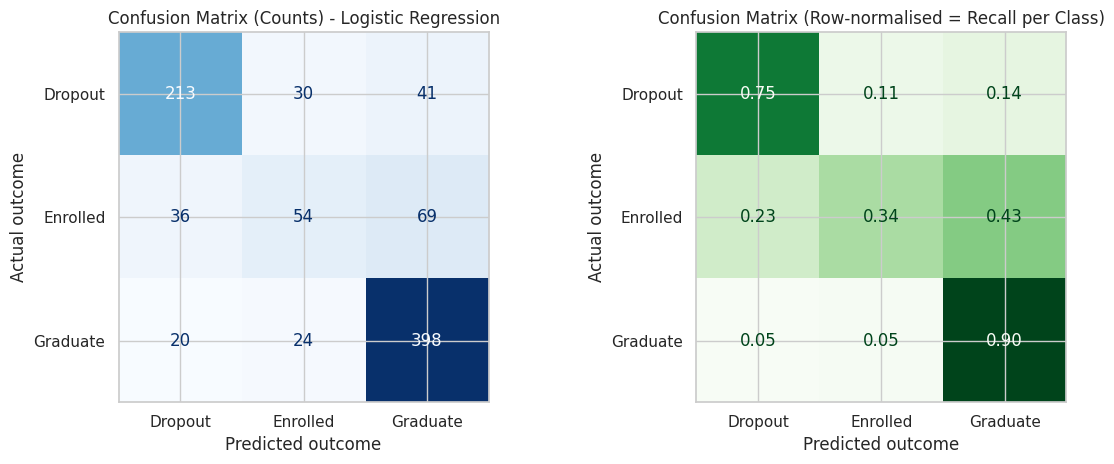

In [43]:
cm = confusion_matrix(y_test, y_pred, labels=ORDER); print(cm)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8))
ConfusionMatrixDisplay(cm, display_labels=ORDER).plot(ax=axs[0], cmap='Blues', colorbar=False)
axs[0].set_title('Confusion Matrix (Counts) - Logistic Regression'); axs[0].set_xlabel('Predicted outcome'); axs[0].set_ylabel('Actual outcome')
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=ORDER, normalize='true'), display_labels=ORDER).plot(ax=axs[1], cmap='Greens', colorbar=False, values_format='.2f')
axs[1].set_title('Confusion Matrix (Row-normalised = Recall per Class)'); axs[1].set_xlabel('Predicted outcome'); axs[1].set_ylabel('Actual outcome')
save('cs4_confusion_matrix')

### B.22 Accuracy, precision, recall and F1-score
**Definitions:** *precision* is the share of students predicted as a class who truly belong to it. *Recall* is the share of a class's students that the model finds. *F1* is their harmonic mean. *Macro-averaged* metrics average the three classes equally, so the minority class counts as much as the majority.

**Interpretation:**
- Accuracy is 0.751, compared with a majority-class baseline of 0.499. Macro precision, recall and F1 are 0.692, 0.663 and 0.671.
- **Graduate** (F1 0.838) and **Dropout** (F1 0.770, precision 0.792, recall 0.750) are predicted well.
- **Enrolled** is weak (F1 0.404, recall 0.340): two-thirds of currently enrolled students are missed.

The gap between accuracy (0.751) and macro F1 (0.671) comes from this weak minority class. The model performs very differently across classes, which the single accuracy figure hides.

               Precision  Recall  F1-score  Support
Dropout            0.792   0.750     0.770    284.0
Enrolled           0.500   0.340     0.404    159.0
Graduate           0.783   0.900     0.838    442.0
Macro average      0.692   0.663     0.671    885.0

Accuracy = 0.751 | Balanced accuracy = 0.663


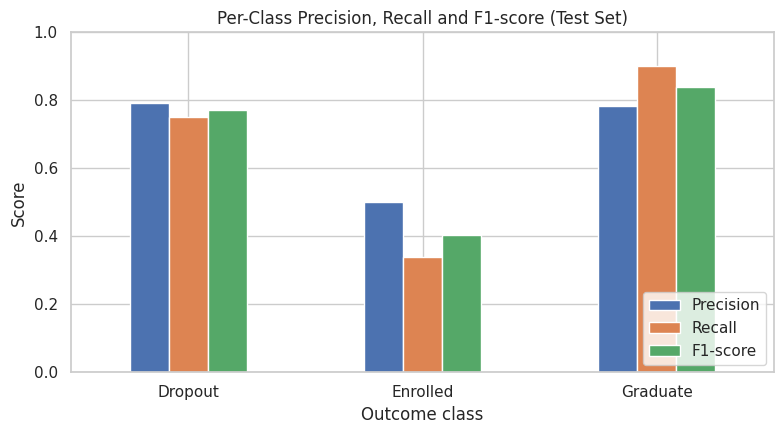

In [44]:
p_, r_, f_, s_ = precision_recall_fscore_support(y_test, y_pred, labels=ORDER)
perf = pd.DataFrame({'Precision': p_, 'Recall': r_, 'F1-score': f_, 'Support': s_}, index=ORDER)
mp, mr, mf, _ = precision_recall_fscore_support(y_test, y_pred, average='macro')
perf.loc['Macro average'] = [mp, mr, mf, s_.sum()]
print(perf.round(3)); print(f'\nAccuracy = {accuracy_score(y_test, y_pred):.3f} | Balanced accuracy = {balanced_accuracy_score(y_test, y_pred):.3f}')
perf.iloc[:3, :3].plot.bar(figsize=(8, 4.5), color=['#4c72b0', '#dd8452', '#55a868'])
plt.title('Per-Class Precision, Recall and F1-score (Test Set)'); plt.xlabel('Outcome class'); plt.ylabel('Score'); plt.ylim(0, 1); plt.xticks(rotation=0); plt.legend(loc='lower right')
save('cs4_per_class_metrics')

### B.23 Effect of class imbalance on evaluation
**Purpose:** test whether `class_weight='balanced'`, which up-weights errors on the smaller classes, improves performance.

**Interpretation:** weighting raises Enrolled recall from 0.340 to 0.566. However, it lowers Dropout recall (0.750 → 0.669) and Graduate recall (0.900 → 0.749), and both accuracy (0.751 → 0.690) and macro F1 (0.671 → 0.652) fall. The unweighted model is kept as the final model because it has the higher macro F1 and finds more of the students who actually drop out, which is the main purpose of an early-warning system.

**What this shows about imbalance:** accuracy is inflated by the majority Graduate class. Always predicting "Graduate" already gives 49.9%, and the 0.751 accuracy conceals an Enrolled recall of only 34%. Macro-averaged and per-class metrics are needed to see this. Any re-weighting decision is a trade-off between classes, and it should follow the institution's priorities, not a single score.

In [45]:
rows = []
for name, cw in [('Unweighted', None), ('Class-weighted (balanced)', 'balanced')]:
    pr = make_model(cw).fit(X_train, y_train).predict(X_test)
    _, rc, f1c, _ = precision_recall_fscore_support(y_test, pr, labels=ORDER)
    rows.append({'Model': name, 'Accuracy': accuracy_score(y_test, pr), 'Macro F1': f1c.mean(), 'Recall Dropout': rc[0], 'Recall Enrolled': rc[1], 'Recall Graduate': rc[2]})
imb = pd.DataFrame(rows).set_index('Model'); print(imb.round(3))
print('Majority-class baseline accuracy (always "Graduate"): {:.3f}'.format((y_test == 'Graduate').mean()))

                           Accuracy  Macro F1  Recall Dropout  Recall Enrolled  Recall Graduate
Model                                                                                          
Unweighted                    0.751     0.671           0.750            0.340            0.900
Class-weighted (balanced)     0.690     0.652           0.669            0.566            0.749
Majority-class baseline accuracy (always "Graduate"): 0.499


### B.24 How much do first-semester results add?
**Observation:** a model using only admission-time information reaches accuracy 0.629 and macro F1 0.521, about 0.15 lower in macro F1 than the model with 1st-semester data. Predictions made at enrolment are much weaker. The first semester provides the decisive information, so the best time for an early check is the end of semester 1.

In [46]:
adm = [c for c in early_features if '1st sem' not in c]
cat_a = [c for c in cat_cols if c in adm]
m_adm = Pipeline([('prep', ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=10), cat_a), ('num', StandardScaler(), [c for c in adm if c not in cat_a])])),
                  ('clf', LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))]).fit(X_train[adm], y_train)
pa = m_adm.predict(X_test[adm])
print(f'Admission-time features only: accuracy = {accuracy_score(y_test, pa):.3f}, macro F1 = {precision_recall_fscore_support(y_test, pa, average="macro")[2]:.3f}')

Admission-time features only: accuracy = 0.629, macro F1 = 0.521


## Part E — Interpretation
### B.25 Logistic regression coefficients
**Purpose:** because numerical features are standardised, each coefficient is the change in the log-odds of a class for a one-standard-deviation increase in that feature, holding others fixed. exp(coefficient) gives the odds multiplier.

**Interpretation (Dropout class):**
- **1st-sem units approved** has the strongest negative coefficient (−1.74, odds × 0.18 per SD). More approved units is associated with much lower dropout odds.
- **1st-sem units enrolled** is positive (+0.82, odds × 2.27). This must be read *together* with units approved: holding approvals fixed, enrolling in more units means failing more of them. The key signal is therefore the **pass rate**.
- **Tuition fees up to date** (−0.60, odds × 0.55) and **scholarship holder** (−0.11) are associated with lower dropout odds; **debtor** status, higher **age** and higher **unemployment rate** (+0.27) with higher odds.
- **Credited units** (+0.43) is associated with higher dropout odds, possibly reflecting transfer students.

These coefficients describe associations within this model. The 1st-semester count variables are correlated with each other, so individual coefficients should not be over-interpreted, and none of them shows that a characteristic *causes* dropout.

Numerical-feature coefficients (standardised), sorted by Dropout coefficient:
                                                Dropout  Enrolled  Graduate
Curricular units 1st sem (approved)              -1.735    -0.351     2.086
Tuition fees up to date                          -0.598     0.077     0.521
Curricular units 1st sem (grade)                 -0.300    -0.155     0.456
Curricular units 1st sem (without evaluations)   -0.172     0.007     0.165
Scholarship holder                               -0.110    -0.126     0.236
Curricular units 1st sem (evaluations)           -0.098     0.382    -0.284
Age at enrollment                                 0.134    -0.044    -0.090
Debtor                                            0.152     0.085    -0.237
Gender                                            0.166    -0.039    -0.127
Unemployment rate                                 0.273    -0.196    -0.077
Curricular units 1st sem (credited)               0.428    -0.238    -0.190
Curricular

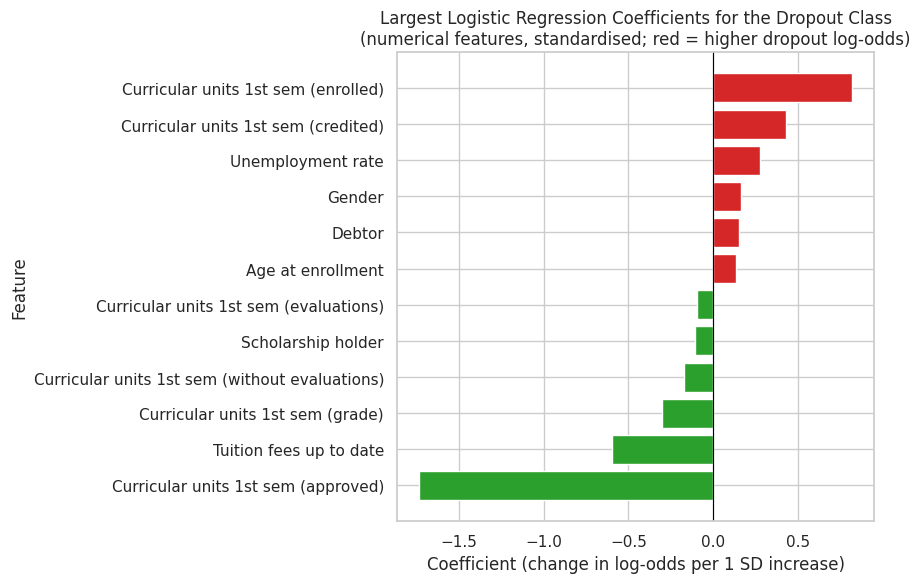


Odds multipliers for Dropout per 1 SD:
Curricular units 1st sem (approved)               0.18
Tuition fees up to date                           0.55
Curricular units 1st sem (grade)                  0.74
Curricular units 1st sem (without evaluations)    0.84
Scholarship holder                                0.90
Curricular units 1st sem (evaluations)            0.91
Age at enrollment                                 1.14
Debtor                                            1.16
Gender                                            1.18
Unemployment rate                                 1.31
Curricular units 1st sem (credited)               1.53
Curricular units 1st sem (enrolled)               2.27
Name: Dropout, dtype: float64


In [47]:
names = model.named_steps['prep'].get_feature_names_out()
coef = pd.DataFrame(model.named_steps['clf'].coef_.T, index=names, columns=model.named_steps['clf'].classes_)
coef.index = coef.index.str.replace('num__', '').str.replace('cat__', '[cat] ')
num_coef = coef[~coef.index.str.startswith('[cat]')]
top = num_coef['Dropout'].sort_values()
show = pd.concat([top.head(6), top.tail(6)])
print('Numerical-feature coefficients (standardised), sorted by Dropout coefficient:'); print(num_coef.loc[show.index].round(3))
plt.figure(figsize=(9, 6))
plt.barh(show.index, show.values, color=['#2ca02c' if v < 0 else '#d62728' for v in show.values])
plt.axvline(0, color='black', lw=.8)
plt.title('Largest Logistic Regression Coefficients for the Dropout Class\n(numerical features, standardised; red = higher dropout log-odds)')
plt.xlabel('Coefficient (change in log-odds per 1 SD increase)'); plt.ylabel('Feature')
save('cs4_dropout_coefficients')
print('\nOdds multipliers for Dropout per 1 SD:'); print(np.exp(show).round(2))

### B.26 Limitations of the model
1. **Poor performance on Enrolled** (F1 0.40, recall 0.34): the model cannot reliably separate students who will still be studying from those who will finish or leave, and about 25% of actual dropouts are still missed.
2. **Linear model:** logistic regression assumes additive effects on the log-odds and cannot capture interactions (e.g. age × course) without manual feature engineering.
3. **Correlated predictors:** the 1st-semester unit counts overlap, which makes individual coefficients unstable and hard to interpret in isolation.
4. **Possible leakage and timing issues:** the timing of *tuition fees up to date* and *debtor* status is not documented. If recorded late, they may partly reflect a decision already taken.
5. **Single institution, single test split:** results come from one Portuguese institution's records and one 80/20 split; cross-validation and external validation would be needed before use elsewhere.
6. **"Enrolled" is not a final outcome:** some currently enrolled students will later drop out or graduate, so this class is inherently noisy.

### B.27 Recommendations (evidence-based)
1. **End-of-semester-1 academic check:** contact every student who approved 0–2 first-semester units (79.4% dropout rate when 0 units are approved), and offer tutoring, study-skills support and course-load advice.
2. **Financial support pathway:** students whose fees are not up to date have an 86.6% dropout rate. Proactive outreach about payment plans, emergency grants and scholarships could be investigated.
3. **Support for mature students:** students who enrolled at 25 or older drop out at more than 50%. Flexible timetabling, evening options and mentoring for students balancing work or family could be piloted.
4. **Monitor engagement, not just grades:** a grade of 0 (no assessments passed) is a stronger warning sign than a low pass grade, so attendance and assessment-submission data should feed into early alerts.

### B.28 Using the model responsibly
- Use predictions only to **offer support**, never to penalise, exclude or limit opportunities for a student.
- Keep a **human in the loop**: advisers review each flag together with context the data does not contain.
- **Exclude or audit sensitive attributes** (gender, nationality, age, parental background), and check that error rates are similar across groups so that no group is flagged unfairly.
- Be transparent with students about what data is used, and allow them to opt out of or correct their records.
- Re-validate the model regularly, as cohorts and economic conditions change.